# Project PULSE
### Public transit analytics and disruption intelligence
**Samyush Rana | Analytical prototype V1.0**

Monitor MBTA predictions, identify geographic concentrations of forecast lateness, and examine shared-trip connectivity. Saved outputs are from November 24, 2026, not live results.

**How to use:** Place this notebook beside the existing `pulse_data`, `pulse_outputs`, and `pulse_collector.py`. Install dependencies from `pulse_requirements.txt`. The historical analysis uses the existing SQLite database. Live API sections are optional; run selectively, especially while the scheduler is active. The original notebook remains unchanged. No scheduler is installed or activated by this notebook.

## 1. Environment and historical data
The database contains repeated prediction observations, not independent realized delays. Collection windows are approximate batch timestamp spans.

In [ ]:
import requests, time, sqlite3
import pandas as pd
import numpy as np
import folium
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
from IPython.display import display

database_path = Path("pulse_data/pulse_history.db")
if not database_path.is_file():
    raise FileNotFoundError("Place the existing pulse_data folder beside this notebook.")
conn = sqlite3.connect(database_path, timeout=60)
conn.execute("PRAGMA foreign_keys = ON")
df_network_routes = pd.read_sql_query("SELECT * FROM routes", conn)
df_routes = df_network_routes.copy()

In [ ]:
# Verify Historical Database Growth

df_snapshot_history = pd.read_sql_query(
    """
    SELECT
        snapshot_id,
        collection_start,
        collection_end,
        total_predictions
    FROM snapshots
    ORDER BY snapshot_id;
    """,
    conn
)

display(df_snapshot_history)

print(
    "Total historical predictions:",
    conn.execute(
        "SELECT COUNT(*) FROM predictions"
    ).fetchone()[0]
)

,snapshot_id,collection_start,collection_end,total_predictions
0,1,2026-11-24T22:26:00.825063Z,2026-11-24T22:51:25.919958Z,37304
1,2,2026-11-24T23:02:42.237810Z,2026-11-24T23:19:19.192241Z,35122


Total historical predictions: 72426


In [ ]:
# Historical Data Quality Analysis

df_historical_quality = pd.read_sql_query(
    """
    SELECT
        snapshot_id,
        COUNT(*) AS total_predictions,

        COUNT(DISTINCT route_id) AS unique_routes,

        COUNT(DISTINCT trip_id) AS unique_trips,

        COUNT(arrival_delay_min)
            AS usable_arrival_predictions,

        COUNT(departure_delay_min)
            AS usable_departure_predictions,

        ROUND(
            100.0 * COUNT(departure_delay_min)
            / COUNT(*),
            2
        ) AS departure_data_completeness_pct

    FROM predictions

    GROUP BY snapshot_id

    ORDER BY snapshot_id;
    """,
    conn
)

display(df_historical_quality)

,snapshot_id,total_predictions,unique_routes,unique_trips,usable_arrival_predictions,usable_departure_predictions,departure_data_completeness_pct
0,1,37304,174,1920,34981,34186,91.64
1,2,35122,174,1842,32901,32130,91.48


In [ ]:
# Identify Routes Without Predictions

df_missing_routes = pd.read_sql_query(
    """
    SELECT
        r.route_id,
        r.route_name,
        r.transit_mode

    FROM routes AS r

    LEFT JOIN predictions AS p
        ON r.route_id = p.route_id
        AND p.snapshot_id = ?

    WHERE p.observation_id IS NULL

    ORDER BY
        r.transit_mode,
        r.route_name;
    """,
    conn,
    params=(snapshot_id,)
)

print("Routes without predictions:", len(df_missing_routes))

display(df_missing_routes)

Routes without predictions: 5


,route_id,route_name,transit_mode
0,171,Logan Airport Terminals - Nubian Station,Bus
1,114,Market Basket - Maverick Station,Bus
2,456,"Salem Depot - Central Square, Lynn",Bus
3,55,West Fenway - Arlington Station,Bus
4,CR-Foxboro,Foxboro Event Service,Commuter Rail


## 2. Live vehicle tracking (optional)
Define the map functions below. Set the flag to True only when you want a fresh API request.

In [ ]:
from datetime import datetime
from zoneinfo import ZoneInfo

def get_pulse_snapshot():
    # 1. Fetch current vehicles
    response = requests.get(
        "https://api-v3.mbta.com/vehicles",
        params={"page[limit]": 1000},
        timeout=30
    )
    response.raise_for_status()

    payload = response.json()
    timestamp = datetime.now(
        ZoneInfo("America/New_York")
    )

    # Check pagination
    if payload.get("links", {}).get("next"):
        raise RuntimeError("Additional API pages need to be fetched.")

    # 2. Extract vehicle information
    records = []

    for vehicle in payload["data"]:
        attrs = vehicle["attributes"]
        route = (
            vehicle.get("relationships", {})
            .get("route", {})
            .get("data")
        )

        records.append({
            "vehicle_id": vehicle["id"],
            "route_id": route["id"] if route else None,
            "latitude": attrs.get("latitude"),
            "longitude": attrs.get("longitude"),
            "current_status": attrs.get("current_status"),
            "updated_at": attrs.get("updated_at"),
            "collected_at": timestamp
        })

    vehicles = pd.DataFrame(records)

    # 3. Join our route inventory
    vehicles = vehicles.merge(
        df_routes[
            ["route_id", "route_name", "transit_mode"]
        ],
        on="route_id",
        how="left",
        validate="many_to_one"
    )

    # 4. Classify services
    vehicles["service_category"] = (
        vehicles["transit_mode"].fillna("Unknown")
    )

    vehicles.loc[
        vehicles["route_id"].eq("Shuttle-Generic"),
        "service_category"
    ] = "Replacement Shuttle"

    return vehicles

In [ ]:
import folium

def create_pulse_map(df):
    pulse_map = folium.Map(
        location=[42.36, -71.06],
        zoom_start=10,
        tiles="OpenStreetMap"
    )

    mode_colors = {
        "Bus": "blue",
        "Subway": "red",
        "Light Rail": "green",
        "Commuter Rail": "purple",
        "Ferry": "cyan",
        "Replacement Shuttle": "orange"
    }

    for mode, color in mode_colors.items():

        mode_data = df[
            df["service_category"] == mode
        ]

        layer = folium.FeatureGroup(
            name=f"{mode} ({len(mode_data)})",
            show=True
        )

        for _, vehicle in mode_data.iterrows():

            if pd.isna(vehicle["latitude"]) or pd.isna(vehicle["longitude"]):
                continue

            folium.CircleMarker(
                location=[
                    vehicle["latitude"],
                    vehicle["longitude"]
                ],
                radius=5,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.8,
                popup=(
                    f"Vehicle: {vehicle['vehicle_id']}<br>"
                    f"Route: {vehicle['route_id']}<br>"
                    f"Mode: {mode}<br>"
                    f"Status: {vehicle['current_status']}"
                )
            ).add_to(layer)

        layer.add_to(pulse_map)

    folium.LayerControl(
        collapsed=False
    ).add_to(pulse_map)

    return pulse_map


In [ ]:
REFRESH_VEHICLES = False
if REFRESH_VEHICLES:
    df_current = get_pulse_snapshot()
    pulse_live_map = create_pulse_map(df_current)
    display(pulse_live_map)

## 3. Trip and route reliability
Forecast departure minus scheduled departure, in minutes. Trip-level aggregation reduces repeated stop weighting. On Schedule means −1 to +5 minutes; thresholds are analyst-defined, not official MBTA on-time performance.

In [ ]:
# Trip-Level Network Performance

df_trip_performance = pd.read_sql_query(
    """
    WITH trip_deviations AS (

        SELECT
            p.snapshot_id,
            r.transit_mode,
            p.route_id,
            p.trip_id,

            AVG(p.departure_delay_min)
                AS trip_avg_deviation

        FROM predictions AS p

        INNER JOIN routes AS r
            ON p.route_id = r.route_id

        WHERE p.departure_delay_min IS NOT NULL
          AND p.trip_id IS NOT NULL

        GROUP BY
            p.snapshot_id,
            r.transit_mode,
            p.route_id,
            p.trip_id
    )

    SELECT
        snapshot_id,
        transit_mode,

        COUNT(*) AS total_trips,

        ROUND(
            AVG(trip_avg_deviation), 2
        ) AS avg_deviation_min,

        ROUND(
            MIN(trip_avg_deviation), 2
        ) AS min_deviation_min,

        ROUND(
            MAX(trip_avg_deviation), 2
        ) AS max_deviation_min

    FROM trip_deviations

    GROUP BY
        snapshot_id,
        transit_mode

    ORDER BY
        snapshot_id,
        avg_deviation_min DESC;
    """,
    conn
)

display(df_trip_performance)

,snapshot_id,transit_mode,total_trips,avg_deviation_min,min_deviation_min,max_deviation_min
0,1,Bus,1342,4.42,-19.03,58.48
1,1,Subway,97,2.10,-1.81,9.32
2,1,Commuter Rail,64,1.13,-5.00,17.58
3,1,Ferry,45,0.23,0.00,3.18
4,1,Light Rail,68,-0.89,-14.61,9.98
5,2,Bus,1269,3.95,-19.18,64.74
6,2,Commuter Rail,65,1.64,-2.07,17.84
7,2,Subway,93,1.61,-2.15,13.19
8,2,Ferry,37,0.13,0.00,1.43
9,2,Light Rail,75,-1.00,-12.37,12.30


In [ ]:
# Classify Trip-Level Schedule Deviations

df_trip_reliability = pd.read_sql_query(
    """
    WITH trip_deviations AS (

        SELECT
            p.snapshot_id,
            r.transit_mode,
            p.route_id,
            p.trip_id,

            AVG(p.departure_delay_min)
                AS trip_avg_deviation

        FROM predictions AS p

        INNER JOIN routes AS r
            ON p.route_id = r.route_id

        WHERE p.departure_delay_min IS NOT NULL
          AND p.trip_id IS NOT NULL

        GROUP BY
            p.snapshot_id,
            r.transit_mode,
            p.route_id,
            p.trip_id
    )

    SELECT
        *,

        ABS(trip_avg_deviation)
            AS absolute_deviation_min,

        CASE
            WHEN trip_avg_deviation < -1
                THEN 'Early'

            WHEN trip_avg_deviation <= 5
                THEN 'On Schedule'

            WHEN trip_avg_deviation <= 15
                THEN 'Minor Delay'

            WHEN trip_avg_deviation <= 30
                THEN 'Major Delay'

            ELSE 'Severe Delay'

        END AS reliability_status

    FROM trip_deviations;
    """,
    conn
)

print("Trip observations:", len(df_trip_reliability))

display(df_trip_reliability.head(10))

Trip observations: 3155


,snapshot_id,transit_mode,route_id,trip_id,trip_avg_deviation,absolute_deviation_min,reliability_status
0,1,Bus,1,78181058,-1.567391,1.567391,Early
1,1,Bus,1,78181060,-0.340152,0.340152,On Schedule
2,1,Bus,1,78181063,-4.542754,4.542754,Early
3,1,Bus,1,78181154,-5.644928,5.644928,Early
4,1,Bus,1,78181156,-6.044928,6.044928,Early
5,1,Bus,1,78181157,-5.197101,5.197101,Early
6,1,Bus,1,78181159,-4.485606,4.485606,Early
7,1,Bus,1,78181163,-4.984058,4.984058,Early
8,1,Bus,1,78182004,-0.012821,0.012821,On Schedule
9,1,Bus,1,78182009,-6.441667,6.441667,Early


In [ ]:
# Network Reliability Summary

df_reliability_summary = (
    df_trip_reliability
    .groupby([
        "snapshot_id",
        "transit_mode",
        "reliability_status"
    ])
    .size()
    .unstack(fill_value=0)
)

status_columns = [
    "Early",
    "On Schedule",
    "Minor Delay",
    "Major Delay",
    "Severe Delay"
]

df_reliability_summary = (
    df_reliability_summary.reindex(
        columns=status_columns,
        fill_value=0
    )
)

df_reliability_summary["Total Trips"] = (
    df_reliability_summary[status_columns]
    .sum(axis=1)
)

df_reliability_summary["On Schedule %"] = (
    df_reliability_summary["On Schedule"]
    / df_reliability_summary["Total Trips"]
    * 100
)

df_reliability_summary["Delayed %"] = (
    df_reliability_summary[
        ["Minor Delay", "Major Delay", "Severe Delay"]
    ].sum(axis=1)
    / df_reliability_summary["Total Trips"]
    * 100
)

display(df_reliability_summary.round(2))

reliability_status         Early  On Schedule  Minor Delay  Major Delay  \
snapshot_id transit_mode                                                  
1           Bus              271          657          273          116   
            Commuter Rail      4           56            3            1   
            Ferry              0           45            0            0   
            Light Rail        37           17           14            0   
            Subway             1           82           14            0   
2           Bus              259          674          224           90   
            Commuter Rail      2           55            7            1   
            Ferry              0           37            0            0   
            Light Rail        44           21           10            0   
            Subway             1           86            6            0   

reliability_status         Severe Delay  Total Trips  On Schedule %  Delayed %  
snapshot_id transit_mode                                                        
1           Bus                      25         1342          48.96      30.85  
            Commuter Rail             0           64          87.50       6.25  
            Ferry                     0           45         100.00       0.00  
            Light Rail                0           68          25.00      20.59  
            Subway                    0           97          84.54      14.43  
2           Bus                      22         1269          53.11      26.48  
            Commuter Rail             0           65          84.62      12.31  
            Ferry                     0           37         100.00       0.00  
            Light Rail                0           75          28.00      13.33  
            Subway                    0           93          92.47       6.45

In [ ]:
# Route-Level Performance Analysis

df_route_performance = (
    df_trip_reliability
    .groupby([
        "snapshot_id",
        "transit_mode",
        "route_id"
    ])
    .agg(
        total_trips=("trip_id", "count"),
        avg_deviation_min=("trip_avg_deviation", "mean"),
        median_deviation_min=("trip_avg_deviation", "median"),
        avg_absolute_deviation=("absolute_deviation_min", "mean"),
        max_deviation_min=("trip_avg_deviation", "max"),
        on_schedule_pct=(
            "reliability_status",
            lambda x: (x == "On Schedule").mean() * 100
        ),
        delayed_pct=(
            "trip_avg_deviation",
            lambda x: (x > 5).mean() * 100
        )
    )
    .reset_index()
)

df_route_performance = df_route_performance.merge(
    df_network_routes[["route_id", "route_name"]],
    on="route_id",
    how="left",
    validate="many_to_one"
)

print("Route-level observations:", len(df_route_performance))

display(df_route_performance.head(10).round(2))

Route-level observations: 346


,snapshot_id,transit_mode,route_id,total_trips,avg_deviation_min,median_deviation_min,avg_absolute_deviation,max_deviation_min,on_schedule_pct,delayed_pct,route_name
0,1,Bus,1,26,-3.69,-4.51,4.56,5.03,15.38,3.85,Harvard Square - Nubian Station
1,1,Bus,10,10,0.31,0.62,2.02,4.56,80.00,0.00,City Point - Arlington Station
2,1,Bus,100,8,-0.01,-0.58,1.56,6.15,50.00,12.50,Elm Street - Wellington Station
3,1,Bus,101,11,3.71,4.68,4.06,8.68,45.45,45.45,Malden Center Station - Sullivan Square Statio...
4,1,Bus,104,13,2.07,1.43,2.61,7.58,61.54,23.08,Malden Center Station - Airport Station
5,1,Bus,105,5,11.26,0.21,11.43,35.56,60.00,40.00,Malden Center Station - Sullivan Square Statio...
6,1,Bus,106,7,3.04,1.86,3.40,8.20,57.14,28.57,Lebanon Loop - Wellington Station
7,1,Bus,108,7,2.49,1.65,3.64,9.76,57.14,14.29,Linden Square - Wellington Station
8,1,Bus,109,20,1.86,0.97,3.17,12.33,55.00,20.00,Linden Square - Harvard Square via Sullivan
9,1,Bus,11,6,-1.49,-1.13,1.85,0.92,50.00,0.00,City Point - Chauncy Street & Summer Street


In [ ]:
# Identify Most Delayed Routes

latest_snapshot = df_route_performance[
    "snapshot_id"
].max()

df_worst_routes = (
    df_route_performance[
        (df_route_performance["snapshot_id"] == latest_snapshot)
        & (df_route_performance["total_trips"] >= 5)
    ]
    .sort_values(
        "avg_deviation_min",
        ascending=False
    )
    .head(15)
)

display(
    df_worst_routes[
        [
            "route_id",
            "route_name",
            "transit_mode",
            "total_trips",
            "avg_deviation_min",
            "max_deviation_min",
            "on_schedule_pct",
            "delayed_pct"
        ]
    ].round(2)
)

,route_id,route_name,transit_mode,total_trips,avg_deviation_min,max_deviation_min,on_schedule_pct,delayed_pct
260,50,Cleary Square - Forest Hills Station,Bus,9,34.00,64.74,0.00,100.00
234,37,Baker Street & Vermont Street - Forest Hills S...,Bus,10,33.66,57.29,0.00,100.00
316,97,Malden Center Station - Wellington Station,Bus,5,29.52,54.65,20.00,80.00
238,40,Georgetowne - Forest Hills Station,Bus,7,26.46,48.76,14.29,85.71
178,105,Malden Center Station - Sullivan Square Statio...,Bus,5,23.61,47.73,20.00,80.00
226,33,River Street & Milton Street - Mattapan Station,Bus,6,19.75,28.63,0.00,100.00
309,90,Davis Station - Assembly Row,Bus,5,17.69,36.99,20.00,80.00
297,76,Lincoln Lab - Alewife Station,Bus,8,11.62,21.00,25.00,75.00
233,36,Millennium Park or VA Hospital - Forest Hills ...,Bus,13,10.17,27.49,46.15,53.85
272,60,Chestnut Hill - Kenmore Station,Bus,7,9.58,20.55,42.86,57.14


In [ ]:
# Directional Performance Analysis

df_direction_performance = pd.read_sql_query(
    """
    WITH trip_direction AS (

        SELECT
            p.snapshot_id,
            p.route_id,
            p.direction_id,
            p.trip_id,

            AVG(p.departure_delay_min)
                AS trip_avg_deviation

        FROM predictions AS p

        WHERE p.departure_delay_min IS NOT NULL
          AND p.trip_id IS NOT NULL
          AND p.direction_id IS NOT NULL

        GROUP BY
            p.snapshot_id,
            p.route_id,
            p.direction_id,
            p.trip_id
    )

    SELECT
        t.snapshot_id,
        t.route_id,
        r.route_name,
        r.transit_mode,
        t.direction_id,

        COUNT(*) AS total_trips,

        ROUND(
            AVG(t.trip_avg_deviation), 2
        ) AS avg_deviation_min,

        ROUND(
            MAX(t.trip_avg_deviation), 2
        ) AS max_deviation_min,

        ROUND(
            100.0 * AVG(
                CASE
                    WHEN t.trip_avg_deviation > 5
                    THEN 1.0
                    ELSE 0.0
                END
            ), 2
        ) AS delayed_pct

    FROM trip_direction AS t

    INNER JOIN routes AS r
        ON t.route_id = r.route_id

    GROUP BY
        t.snapshot_id,
        t.route_id,
        r.route_name,
        r.transit_mode,
        t.direction_id

    ORDER BY
        t.snapshot_id,
        avg_deviation_min DESC;
    """,
    conn
)

print(
    "Directional observations:",
    len(df_direction_performance)
)

display(df_direction_performance.head(10))

Directional observations: 679


,snapshot_id,route_id,route_name,transit_mode,direction_id,total_trips,avg_deviation_min,max_deviation_min,delayed_pct
0,1,50,Cleary Square - Forest Hills Station,Bus,1,4,39.42,58.48,100.00
1,1,37,Baker Street & Vermont Street - Forest Hills S...,Bus,1,3,31.22,45.97,100.00
2,1,37,Baker Street & Vermont Street - Forest Hills S...,Bus,0,6,31.21,50.34,83.33
3,1,40,Georgetowne - Forest Hills Station,Bus,0,4,30.91,50.83,100.00
4,1,40,Georgetowne - Forest Hills Station,Bus,1,2,29.33,41.03,100.00
5,1,50,Cleary Square - Forest Hills Station,Bus,0,3,29.06,55.47,100.00
6,1,451,North Beverly Station - Salem Depot,Bus,0,1,25.41,25.41,100.00
7,1,36,Millennium Park or VA Hospital - Forest Hills ...,Bus,1,5,19.79,28.65,100.00
8,1,33,River Street & Milton Street - Mattapan Station,Bus,0,3,19.44,30.09,100.00
9,1,31,Mattapan Station - Forest Hills Station via Mo...,Bus,1,9,19.37,39.17,77.78


## 4. Prediction horizons and hotspot detection
Near-term forecasts are 0–15 minutes from the batch collection timestamp. A hotspot requires at least three trip observations, two routes and mean deviation above five minutes. Horizon comparisons do not measure forecast accuracy.

In [ ]:
# Calculate Prediction Horizons

df_prediction_horizon = pd.read_sql_query(
    """
    SELECT
        p.snapshot_id,
        p.prediction_id,
        p.route_id,
        r.transit_mode,
        p.trip_id,
        p.stop_id,
        p.direction_id,
        p.collected_at,
        p.predicted_departure,
        p.departure_delay_min,

        (
            JULIANDAY(p.predicted_departure)
            - JULIANDAY(p.collected_at)
        ) * 1440 AS prediction_horizon_min

    FROM predictions AS p

    INNER JOIN routes AS r
        ON p.route_id = r.route_id

    WHERE p.departure_delay_min IS NOT NULL
      AND p.predicted_departure IS NOT NULL
      AND p.collected_at IS NOT NULL;
    """,
    conn
)

print("Usable observations:", len(df_prediction_horizon))

print("\nPrediction horizon statistics:")

display(
    df_prediction_horizon[
        "prediction_horizon_min"
    ].describe().round(2)
)

print(
    "\nNegative prediction horizons:",
    (df_prediction_horizon["prediction_horizon_min"] < 0).sum()
)

Usable observations: 66316

Prediction horizon statistics:


count    66316.00
mean        36.42
std         23.07
min        -12.20
25%         16.83
50%         34.84
75%         54.47
max        109.15
Name: prediction_horizon_min, dtype: float64


Negative prediction horizons: 777


In [ ]:
# Prediction Horizon Analysis

df_horizon_analysis = df_prediction_horizon[
    df_prediction_horizon["prediction_horizon_min"] >= 0
].copy()

df_horizon_analysis["horizon_category"] = pd.cut(
    df_horizon_analysis["prediction_horizon_min"],
    bins=[0, 15, 30, 60, 120, float("inf")],
    labels=[
        "0-15 min",
        "15-30 min",
        "30-60 min",
        "60-120 min",
        "120+ min"
    ],
    include_lowest=True
)

df_horizon_analysis["absolute_deviation"] = (
    df_horizon_analysis["departure_delay_min"].abs()
)

df_horizon_summary = (
    df_horizon_analysis
    .groupby("horizon_category", observed=True)
    .agg(
        total_predictions=("prediction_id", "count"),
        avg_deviation_min=("departure_delay_min", "mean"),
        median_deviation_min=("departure_delay_min", "median"),
        avg_absolute_deviation=("absolute_deviation", "mean"),
        std_deviation_min=("departure_delay_min", "std"),
        delayed_pct=(
            "departure_delay_min",
            lambda x: (x > 5).mean() * 100
        )
    )
    .reset_index()
)

display(df_horizon_summary.round(2))

,horizon_category,total_predictions,avg_deviation_min,median_deviation_min,avg_absolute_deviation,std_deviation_min,delayed_pct
0,0-15 min,14179,6.60,4.12,7.41,9.18,44.99
1,15-30 min,13810,4.57,1.88,5.70,8.46,31.15
2,30-60 min,25430,2.56,0.78,4.27,7.43,19.44
3,60-120 min,12120,0.67,0.00,3.78,6.28,11.91


In [ ]:
# Extract Near-Term Stop Predictions

df_immediate_predictions = df_prediction_horizon[
    (
        df_prediction_horizon["prediction_horizon_min"]
        >= 0
    )
    &
    (
        df_prediction_horizon["prediction_horizon_min"]
        <= 15
    )
    &
    (
        df_prediction_horizon["snapshot_id"]
        == latest_snapshot
    )
].dropna(
    subset=["stop_id", "trip_id"]
).copy()

print(
    "Near-term predictions:",
    len(df_immediate_predictions)
)

print(
    "Unique stops:",
    df_immediate_predictions["stop_id"].nunique()
)

print(
    "Unique routes:",
    df_immediate_predictions["route_id"].nunique()
)

print(
    "Unique trips:",
    df_immediate_predictions["trip_id"].nunique()
)

display(df_immediate_predictions.head())

Near-term predictions: 7056
Unique stops: 4363
Unique routes: 169
Unique trips: 845


,snapshot_id,prediction_id,route_id,transit_mode,trip_id,stop_id,direction_id,collected_at,predicted_departure,departure_delay_min,prediction_horizon_min
34190,2,prediction-77871453-70061-1-Red,Red,Subway,77871453,70061,0,2026-11-24T23:02:42.237810Z,2026-11-24T23:15:15.000000Z,1.250000,12.546033
34191,2,prediction-77871452-Alewife-02-1-Red,Red,Subway,77871452,Alewife-02,0,2026-11-24T23:02:42.237810Z,2026-11-24T23:05:00.000000Z,1.000000,2.296033
34197,2,prediction-77871341-70105-1-Red,Red,Subway,77871341,70105,1,2026-11-24T23:02:42.237810Z,2026-11-24T23:11:07.000000Z,3.116667,8.412700
34200,2,prediction-77871193-70094-50-Red,Red,Subway,77871193,70094,1,2026-11-24T23:02:42.237810Z,2026-11-24T23:14:00.000000Z,1.000000,11.296033
34201,2,prediction-77871187-70094-50-Red,Red,Subway,77871187,70094,1,2026-11-24T23:02:42.237810Z,2026-11-24T23:06:00.000000Z,3.000000,3.296033


In [ ]:
# Detect Potential Stop-Level Hotspots

df_stop_trip = (
    df_immediate_predictions
    .groupby([
        "stop_id",
        "route_id",
        "trip_id"
    ])
    .agg(
        trip_deviation_min=(
            "departure_delay_min", "mean"
        )
    )
    .reset_index()
)

df_stop_hotspots = (
    df_stop_trip
    .groupby("stop_id")
    .agg(
        total_trips=("trip_id", "count"),

        affected_routes=("route_id", "nunique"),

        avg_deviation_min=(
            "trip_deviation_min", "mean"
        ),

        median_deviation_min=(
            "trip_deviation_min", "median"
        ),

        max_deviation_min=(
            "trip_deviation_min", "max"
        ),

        delayed_pct=(
            "trip_deviation_min",
            lambda x: (x > 5).mean() * 100
        )
    )
    .reset_index()
)

df_stop_hotspots = (
    df_stop_hotspots[
        (df_stop_hotspots["total_trips"] >= 3)
        &
        (df_stop_hotspots["affected_routes"] >= 2)
        &
        (df_stop_hotspots["avg_deviation_min"] > 5)
    ]
    .sort_values(
        "avg_deviation_min",
        ascending=False
    )
)

print(
    "Potential disruption hotspots:",
    len(df_stop_hotspots)
)

display(df_stop_hotspots.head(20).round(2))

Potential disruption hotspots: 234


,stop_id,total_trips,affected_routes,avg_deviation_min,median_deviation_min,max_deviation_min,delayed_pct
2989,637,8,5,29.84,23.94,57.32,87.50
2997,638,8,5,29.44,23.36,56.57,87.50
2998,639,8,5,28.83,22.78,56.03,87.50
2985,636,8,5,28.70,23.08,56.23,87.50
3008,640,8,5,28.47,22.51,56.33,87.50
3048,6507,4,2,27.74,20.18,63.72,100.00
3680,788,5,3,27.54,23.18,54.75,100.00
3049,6508,4,2,27.22,19.91,62.98,100.00
3677,787,6,3,26.98,22.74,55.13,100.00
3689,789,6,3,26.76,22.33,55.03,100.00


## 5. Geographic metadata and spatial clustering
DBSCAN uses a 500 m haversine neighborhood and at least three samples. Cluster IDs are local to each analysis, and proximity does not imply causation. The next cell retrieves stop metadata from the API; run when the collector is idle.

In [ ]:
# Retrieve Hotspot Geographic Information

def get_pulse_stop_metadata(stop_ids, batch_size=50):

    stop_ids = list(dict.fromkeys(map(str, stop_ids)))
    records = []
    failed_batches = []

    for i in range(0, len(stop_ids), batch_size):

        batch = stop_ids[i:i + batch_size]

        print(
            f"Retrieving stop batch "
            f"{i // batch_size + 1}/"
            f"{(len(stop_ids) + batch_size - 1) // batch_size}"
        )

        url = "https://api-v3.mbta.com/stops"

        params = {
            "filter[id]": ",".join(batch),
            "page[limit]": 100
        }

        try:

            for attempt in range(5):

                response = requests.get(
                    url,
                    params=params,
                    timeout=30
                )

                if response.status_code == 429:

                    retry_after = response.headers.get(
                        "Retry-After", ""
                    )

                    wait_time = (
                        int(retry_after)
                        if retry_after.isdigit()
                        else 5 * (2 ** attempt)
                    )

                    print(
                        f"Rate limit reached. "
                        f"Waiting {wait_time} seconds."
                    )

                    time.sleep(wait_time)

                else:
                    break

            response.raise_for_status()

            for stop in response.json().get("data", []):

                attrs = stop["attributes"]
                rels = stop.get("relationships", {})

                parent = (
                    rels.get("parent_station", {})
                    .get("data") or {}
                )

                records.append({
                    "stop_id": stop["id"],
                    "stop_name": attrs.get("name"),
                    "latitude": attrs.get("latitude"),
                    "longitude": attrs.get("longitude"),
                    "location_type": attrs.get("location_type"),
                    "parent_station": parent.get("id")
                })

        except requests.RequestException as error:

            failed_batches.append(batch)
            print("Batch failed:", error)

        time.sleep(1)

    df_metadata = pd.DataFrame(
        records,
        columns=[
            "stop_id",
            "stop_name",
            "latitude",
            "longitude",
            "location_type",
            "parent_station"
        ]
    )

    df_metadata = df_metadata.drop_duplicates(
        subset=["stop_id"]
    )

    print("\nStop metadata collection complete.")
    print("Stops requested:", len(stop_ids))
    print("Stops retrieved:", len(df_metadata))
    print("Failed batches:", len(failed_batches))

    return df_metadata, failed_batches

In [ ]:
# Collect Hotspot Stop Metadata

hotspot_stop_ids = (
    df_stop_hotspots["stop_id"]
    .astype(str)
    .unique()
    .tolist()
)

df_hotspot_metadata, failed_stop_batches = (
    get_pulse_stop_metadata(hotspot_stop_ids)
)

display(df_hotspot_metadata.head(10))

Retrieving stop batch 1/5
Retrieving stop batch 2/5
Retrieving stop batch 3/5
Retrieving stop batch 4/5
Retrieving stop batch 5/5

Stop metadata collection complete.
Stops requested: 234
Stops retrieved: 234
Failed batches: 0


,stop_id,stop_name,latitude,longitude,location_type,parent_station
0,637,Washington St @ Firth Rd,42.288780,-71.125513,0,None
1,638,Washington St @ Granfield Ave,42.290089,-71.124166,0,None
2,639,Washington St @ Whipple Ave,42.291606,-71.122523,0,None
3,636,Washington St @ Cummins Hwy,42.286751,-71.127702,0,None
4,640,Washington St @ Archdale Rd,42.292634,-71.121390,0,None
5,6507,Hyde Park Ave @ West St,42.261535,-71.122300,0,None
6,788,Belgrade Ave @ Iona St,42.285984,-71.145019,0,None
7,6508,Hyde Park Ave opp Webster St,42.258967,-71.123477,0,None
8,787,Belgrade Ave @ West Roxbury Pkwy,42.285932,-71.147524,0,None
9,789,Belgrade Ave @ Rexhame St,42.286017,-71.143322,0,None


In [ ]:
# Merge Hotspots with Geographic Information

df_hotspots_geo = df_stop_hotspots.copy()

df_hotspots_geo["stop_id"] = (
    df_hotspots_geo["stop_id"].astype(str)
)

df_hotspots_geo = df_hotspots_geo.merge(
    df_hotspot_metadata,
    on="stop_id",
    how="left",
    validate="one_to_one"
)

print("Total hotspots:", len(df_hotspots_geo))

print(
    "Missing stop names:",
    df_hotspots_geo["stop_name"].isna().sum()
)

print(
    "Missing coordinates:",
    df_hotspots_geo[
        ["latitude", "longitude"]
    ].isna().any(axis=1).sum()
)

display(
    df_hotspots_geo[
        [
            "stop_id",
            "stop_name",
            "latitude",
            "longitude",
            "total_trips",
            "affected_routes",
            "avg_deviation_min",
            "delayed_pct"
        ]
    ].head(20).round(4)
)

Total hotspots: 234
Missing stop names: 0
Missing coordinates: 0


,stop_id,stop_name,latitude,longitude,total_trips,affected_routes,avg_deviation_min,delayed_pct
0,637,Washington St @ Firth Rd,42.2888,-71.1255,8,5,29.8375,87.5000
1,638,Washington St @ Granfield Ave,42.2901,-71.1242,8,5,29.4354,87.5000
2,639,Washington St @ Whipple Ave,42.2916,-71.1225,8,5,28.8333,87.5000
3,636,Washington St @ Cummins Hwy,42.2868,-71.1277,8,5,28.7000,87.5000
4,640,Washington St @ Archdale Rd,42.2926,-71.1214,8,5,28.4688,87.5000
5,6507,Hyde Park Ave @ West St,42.2615,-71.1223,4,2,27.7375,100.0000
6,788,Belgrade Ave @ Iona St,42.2860,-71.1450,5,3,27.5400,100.0000
7,6508,Hyde Park Ave opp Webster St,42.2590,-71.1235,4,2,27.2208,100.0000
8,787,Belgrade Ave @ West Roxbury Pkwy,42.2859,-71.1475,6,3,26.9750,100.0000
9,789,Belgrade Ave @ Rexhame St,42.2860,-71.1433,6,3,26.7639,100.0000


In [ ]:
# Create PULSE Disruption Map

import folium

def create_pulse_disruption_map(df):

    valid_stops = df.dropna(
        subset=["latitude", "longitude"]
    ).copy()

    disruption_map = folium.Map(
        location=[
            valid_stops["latitude"].mean(),
            valid_stops["longitude"].mean()
        ],
        zoom_start=11,
        tiles="OpenStreetMap"
    )

    minor_layer = folium.FeatureGroup(
        name="Minor Delay (5-15 min)"
    )

    major_layer = folium.FeatureGroup(
        name="Major Delay (15-30 min)"
    )

    severe_layer = folium.FeatureGroup(
        name="Severe Delay (30+ min)"
    )

    for _, stop in valid_stops.iterrows():

        delay = stop["avg_deviation_min"]

        if delay > 30:
            color = "#DC2626"
            layer = severe_layer

        elif delay > 15:
            color = "#EA580C"
            layer = major_layer

        else:
            color = "#EAB308"
            layer = minor_layer

        popup_text = f"""
        <b>{stop['stop_name']}</b><br><br>

        Stop ID: {stop['stop_id']}<br>

        Average predicted lateness:
        {delay:.2f} minutes<br>

        Maximum predicted lateness:
        {stop['max_deviation_min']:.2f} minutes<br>

        Trip observations:
        {stop['total_trips']}<br>

        Routes represented:
        {stop['affected_routes']}<br>

        Predicted delayed:
        {stop['delayed_pct']:.2f}%
        """

        folium.CircleMarker(
            location=[
                stop["latitude"],
                stop["longitude"]
            ],
            radius=4 + min(delay / 4, 10),
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=0.75,
            weight=1,
            popup=folium.Popup(
                popup_text,
                max_width=350
            ),
            tooltip=(
                f"{stop['stop_name']} | "
                f"{delay:.1f} min"
            )
        ).add_to(layer)

    minor_layer.add_to(disruption_map)
    major_layer.add_to(disruption_map)
    severe_layer.add_to(disruption_map)

    folium.LayerControl(
        collapsed=False
    ).add_to(disruption_map)

    disruption_map.fit_bounds(
        valid_stops[
            ["latitude", "longitude"]
        ].values.tolist()
    )

    return disruption_map

In [ ]:
if df_hotspots_geo.dropna(subset=["latitude", "longitude"]).empty:
    raise RuntimeError("No geocoded hotspots for this snapshot; skip the cluster sections.")

In [ ]:
# Display PULSE Disruption Map

pulse_disruption_map = (
    create_pulse_disruption_map(
        df_hotspots_geo
    )
)

display(pulse_disruption_map)

In [ ]:
# DBSCAN Spatial Clustering

import numpy as np

from sklearn.cluster import DBSCAN

df_hotspot_clusters = (
    df_hotspots_geo.dropna(
        subset=["latitude", "longitude"]
    ).copy()
)

coordinates = np.radians(
    df_hotspot_clusters[
        ["latitude", "longitude"]
    ].to_numpy()
)

earth_radius_km = 6371.0088

cluster_radius_km = 0.5

dbscan_model = DBSCAN(
    eps=cluster_radius_km / earth_radius_km,
    min_samples=3,
    metric="haversine",
    algorithm="ball_tree"
)

df_hotspot_clusters["cluster_id"] = (
    dbscan_model.fit_predict(coordinates)
)

cluster_labels = (
    df_hotspot_clusters["cluster_id"]
)

number_of_clusters = len(
    set(cluster_labels) - {-1}
)

print("PULSE SPATIAL CLUSTERING RESULTS")

print(
    "Total hotspots:",
    len(df_hotspot_clusters)
)

print(
    "Geographic clusters:",
    number_of_clusters
)

print(
    "Clustered hotspots:",
    (cluster_labels != -1).sum()
)

print(
    "Unclustered hotspots:",
    (cluster_labels == -1).sum()
)

display(
    df_hotspot_clusters[
        [
            "stop_id",
            "stop_name",
            "avg_deviation_min",
            "cluster_id"
        ]
    ].head(20)
)

PULSE SPATIAL CLUSTERING RESULTS
Total hotspots: 234
Geographic clusters: 17
Clustered hotspots: 212
Unclustered hotspots: 22


,stop_id,stop_name,avg_deviation_min,cluster_id
0,637,Washington St @ Firth Rd,29.837500,0
1,638,Washington St @ Granfield Ave,29.435417,0
2,639,Washington St @ Whipple Ave,28.833333,0
3,636,Washington St @ Cummins Hwy,28.700000,0
4,640,Washington St @ Archdale Rd,28.468750,0
5,6507,Hyde Park Ave @ West St,27.737500,1
6,788,Belgrade Ave @ Iona St,27.540000,0
7,6508,Hyde Park Ave opp Webster St,27.220833,1
8,787,Belgrade Ave @ West Roxbury Pkwy,26.975000,0
9,789,Belgrade Ave @ Rexhame St,26.763889,0


In [ ]:
# Connect Geographic Clusters to Trips

df_cluster_trips = df_stop_trip.merge(
    df_hotspot_clusters[
        ["stop_id", "cluster_id"]
    ],
    on="stop_id",
    how="inner",
    validate="many_to_one"
)

# Exclude unclustered hotspots from cluster analysis

df_cluster_trips = df_cluster_trips[
    df_cluster_trips["cluster_id"] != -1
].copy()

# Aggregate each trip once per cluster

df_cluster_trip_unique = (
    df_cluster_trips
    .groupby([
        "cluster_id",
        "route_id",
        "trip_id"
    ])
    .agg(
        trip_avg_deviation=(
            "trip_deviation_min", "mean"
        ),
        stops_visited=("stop_id", "nunique")
    )
    .reset_index()
)

print(
    "Original stop-trip observations:",
    len(df_cluster_trips)
)

print(
    "Deduplicated cluster-trip observations:",
    len(df_cluster_trip_unique)
)

display(df_cluster_trip_unique.head(10))

Original stop-trip observations: 892
Deduplicated cluster-trip observations: 239


,cluster_id,route_id,trip_id,trip_avg_deviation,stops_visited
0,0,14,78942567,-0.300000,2
1,0,34,78942102,0.736667,10
2,0,34,78942103,9.705556,3
3,0,34,78942104,14.188095,7
4,0,34E,78942212,15.779167,8
5,0,35,78941007,3.488095,7
6,0,35,78941016,4.612821,13
7,0,35,78941062,1.292857,14
8,0,36,78940928,15.519444,12
9,0,36,78941025,22.365833,20


In [ ]:
# Cluster Performance Analysis

df_cluster_summary = (
    df_cluster_trip_unique
    .groupby("cluster_id")
    .agg(
        total_trips=("trip_id", "count"),

        total_routes=("route_id", "nunique"),

        avg_deviation_min=(
            "trip_avg_deviation", "mean"
        ),

        median_deviation_min=(
            "trip_avg_deviation", "median"
        ),

        max_deviation_min=(
            "trip_avg_deviation", "max"
        ),

        delayed_pct=(
            "trip_avg_deviation",
            lambda x: (x > 5).mean() * 100
        ),

        severe_trips=(
            "trip_avg_deviation",
            lambda x: (x > 30).sum()
        )
    )
    .reset_index()
)

df_cluster_geography = (
    df_hotspot_clusters[
        df_hotspot_clusters["cluster_id"] != -1
    ]
    .groupby("cluster_id")
    .agg(
        total_hotspots=("stop_id", "nunique"),
        center_latitude=("latitude", "mean"),
        center_longitude=("longitude", "mean")
    )
    .reset_index()
)

df_cluster_summary = df_cluster_summary.merge(
    df_cluster_geography,
    on="cluster_id",
    validate="one_to_one"
)

df_cluster_summary = (
    df_cluster_summary.sort_values(
        "avg_deviation_min",
        ascending=False
    )
)

display(df_cluster_summary.round(2))

,cluster_id,total_trips,total_routes,avg_deviation_min,median_deviation_min,max_deviation_min,delayed_pct,severe_trips,total_hotspots,center_latitude,center_longitude
1,1,9,2,21.83,12.20,63.77,100.00,2,6,42.26,-71.12
0,0,23,9,14.69,9.71,55.57,60.87,3,47,42.29,-71.14
2,2,16,8,14.18,9.37,48.70,62.50,2,16,42.41,-71.06
3,3,12,7,11.35,3.46,48.82,41.67,2,6,42.40,-71.07
4,4,4,2,11.25,8.39,28.08,50.00,0,5,42.41,-71.15
5,5,30,10,10.33,8.59,26.16,63.33,0,26,42.38,-71.13
7,7,14,4,9.38,5.06,26.86,50.00,0,19,42.28,-71.09
9,9,8,6,8.46,5.24,23.24,50.00,0,9,42.30,-71.07
12,12,4,4,7.49,5.88,15.62,75.00,0,3,42.37,-71.10
8,8,15,7,6.62,3.85,19.32,40.00,0,4,42.43,-71.07


In [ ]:
# Cluster Route Intelligence

df_cluster_routes = (
    df_cluster_trip_unique
    .groupby([
        "cluster_id",
        "route_id"
    ])
    .agg(
        total_trips=("trip_id", "count"),
        avg_deviation_min=(
            "trip_avg_deviation", "mean"
        ),
        delayed_pct=(
            "trip_avg_deviation",
            lambda x: (x > 5).mean() * 100
        )
    )
    .reset_index()
)

df_cluster_routes = df_cluster_routes.merge(
    df_network_routes[
        ["route_id", "route_name", "transit_mode"]
    ],
    on="route_id",
    how="left",
    validate="many_to_one"
)

df_cluster_routes = (
    df_cluster_routes.sort_values(
        ["cluster_id", "avg_deviation_min"],
        ascending=[True, False]
    )
)

print("Cluster 0 - Route Analysis")

display(
    df_cluster_routes[
        df_cluster_routes["cluster_id"] == 0
    ].round(2)
)

print("\nCluster 1 - Route Analysis")

display(
    df_cluster_routes[
        df_cluster_routes["cluster_id"] == 1
    ].round(2)
)

Cluster 0 - Route Analysis


,cluster_id,route_id,total_trips,avg_deviation_min,delayed_pct,route_name,transit_mode
5,0,37,3,38.68,100.00,Baker Street & Vermont Street - Forest Hills S...,Bus
8,0,40,2,36.28,100.00,Georgetowne - Forest Hills Station,Bus
2,0,34E,1,15.78,100.00,Walpole Center - Forest Hills Station,Bus
4,0,36,7,14.06,85.71,Millennium Park or VA Hospital - Forest Hills ...,Bus
1,0,34,3,8.21,66.67,Dedham Mall - Forest Hills Station,Bus
3,0,35,3,3.13,0.00,Dedham Mall or Stimson Street - Forest Hills S...,Bus
6,0,38,1,1.47,0.00,Wren Street - Forest Hills Station,Bus
7,0,39,2,0.00,0.00,Forest Hills Station - Back Bay Station,Bus
0,0,14,1,-0.30,0.00,Roslindale Square - Heath Street,Bus



Cluster 1 - Route Analysis


,cluster_id,route_id,total_trips,avg_deviation_min,delayed_pct,route_name,transit_mode
10,1,50,3,40.43,100.0,Cleary Square - Forest Hills Station,Bus
9,1,32,6,12.52,100.0,Wolcott Square - Forest Hills Station,Bus


In [ ]:
# PULSE Geographic Cluster Map

import folium

def create_pulse_cluster_map(df_stops, df_summary):

    cluster_map = folium.Map(
        location=[
            df_stops["latitude"].mean(),
            df_stops["longitude"].mean()
        ],
        zoom_start=11,
        tiles="OpenStreetMap"
    )

    colors = [
        "#e6194b", "#3cb44b", "#4363d8",
        "#f58231", "#911eb4", "#42d4f4",
        "#f032e6", "#bfef45", "#469990",
        "#9a6324", "#800000", "#808000",
        "#000075", "#fabed4", "#aaffc3",
        "#dcbeff", "#ffd8b1"
    ]

    for cluster_id in sorted(
        df_stops["cluster_id"].unique()
    ):

        cluster_stops = df_stops[
            df_stops["cluster_id"] == cluster_id
        ]

        if cluster_id == -1:

            color = "#808080"
            layer_name = "Unclustered Hotspots"

        else:

            color = colors[cluster_id % len(colors)]
            layer_name = f"Cluster {cluster_id}"

        layer = folium.FeatureGroup(
            name=layer_name
        )

        for _, stop in cluster_stops.iterrows():

            folium.CircleMarker(
                location=[
                    stop["latitude"],
                    stop["longitude"]
                ],
                radius=6,
                color=color,
                fill=True,
                fill_color=color,
                fill_opacity=0.8,
                weight=1,
                tooltip=stop["stop_name"],
                popup=folium.Popup(
                    f"""
                    <b>{stop['stop_name']}</b><br>
                    Cluster: {cluster_id}<br>
                    Average predicted deviation:
                    {stop['avg_deviation_min']:.2f} min
                    """,
                    max_width=300
                )
            ).add_to(layer)

        layer.add_to(cluster_map)

    summary_layer = folium.FeatureGroup(
        name="Cluster Intelligence"
    )

    for _, cluster in df_summary.iterrows():

        popup_text = f"""
        <b>PULSE Cluster {int(cluster['cluster_id'])}</b>
        <br><br>

        Hotspots: {int(cluster['total_hotspots'])}<br>

        Routes: {int(cluster['total_routes'])}<br>

        Trip observations:
        {int(cluster['total_trips'])}<br>

        Average predicted deviation:
        {cluster['avg_deviation_min']:.2f} min<br>

        Predicted delayed:
        {cluster['delayed_pct']:.2f}%<br>

        Severe trip deviations:
        {int(cluster['severe_trips'])}
        """

        folium.Marker(
            location=[
                cluster["center_latitude"],
                cluster["center_longitude"]
            ],
            popup=folium.Popup(
                popup_text,
                max_width=350
            ),
            tooltip=(
                f"Cluster {int(cluster['cluster_id'])}"
            ),
            icon=folium.Icon(
                color="darkblue",
                icon="info-sign"
            )
        ).add_to(summary_layer)

    summary_layer.add_to(cluster_map)

    folium.LayerControl(
        collapsed=True
    ).add_to(cluster_map)

    cluster_map.fit_bounds(
        df_stops[
            ["latitude", "longitude"]
        ].values.tolist()
    )

    return cluster_map

In [ ]:
# Display PULSE Cluster Map

pulse_cluster_map = create_pulse_cluster_map(
    df_hotspot_clusters,
    df_cluster_summary
)

display(pulse_cluster_map)

## 6. Disruption priority and network connectivity
The experimental DPI weights severity (50%), route exposure (30%) and delayed-trip share (20%). It is not a probability or passenger-impact measure. Undirected graph edges represent shared trips, not demonstrated propagation.

In [ ]:
# PULSE Disruption Priority Index

df_cluster_priority = df_cluster_summary.copy()

# Normalize each component to a 0-1 scale

df_cluster_priority["severity_score"] = (
    df_cluster_priority["avg_deviation_min"] / 30
).clip(0, 1)

df_cluster_priority["exposure_score"] = (
    df_cluster_priority["total_routes"] / 20
).clip(0, 1)

df_cluster_priority["delay_proportion_score"] = (
    df_cluster_priority["delayed_pct"] / 100
).clip(0, 1)

# Calculate weighted priority score

df_cluster_priority["pulse_dpi"] = 100 * (
    0.50 * df_cluster_priority["severity_score"]
    + 0.30 * df_cluster_priority["exposure_score"]
    + 0.20 * df_cluster_priority["delay_proportion_score"]
)

df_cluster_priority = (
    df_cluster_priority.sort_values(
        "pulse_dpi",
        ascending=False
    )
)

display(
    df_cluster_priority[
        [
            "cluster_id",
            "total_hotspots",
            "total_routes",
            "total_trips",
            "avg_deviation_min",
            "delayed_pct",
            "pulse_dpi"
        ]
    ].round(2)
)

,cluster_id,total_hotspots,total_routes,total_trips,avg_deviation_min,delayed_pct,pulse_dpi
1,1,6,2,9,21.83,100.00,59.38
0,0,47,9,23,14.69,60.87,50.16
2,2,16,8,16,14.18,62.50,48.13
5,5,26,10,30,10.33,63.33,44.88
6,6,41,17,58,6.36,43.10,44.72
3,3,6,7,12,11.35,41.67,37.75
12,12,3,4,4,7.49,75.00,33.49
9,9,9,6,8,8.46,50.00,33.09
4,4,5,2,4,11.25,50.00,31.75
7,7,19,4,14,9.38,50.00,31.63


In [ ]:
# Identify Shared Trips Between Clusters

from itertools import combinations

cluster_connections = []

for (route_id, trip_id), group in (
    df_cluster_trip_unique.groupby(
        ["route_id", "trip_id"]
    )
):

    clusters = sorted(
        group["cluster_id"].unique()
    )

    if len(clusters) >= 2:

        for cluster_a, cluster_b in combinations(
            clusters, 2
        ):

            cluster_connections.append({
                "cluster_a": cluster_a,
                "cluster_b": cluster_b,
                "route_id": route_id,
                "trip_id": trip_id
            })

df_cluster_connections = pd.DataFrame(
    cluster_connections,
    columns=[
        "cluster_a",
        "cluster_b",
        "route_id",
        "trip_id"
    ]
)

print(
    "Shared trip connections:",
    len(df_cluster_connections)
)

print(
    "Distinct connecting trips:",
    df_cluster_connections[
        ["route_id", "trip_id"]
    ].drop_duplicates().shape[0]
)

display(df_cluster_connections.head(15))

Shared trip connections: 17
Distinct connecting trips: 17


,cluster_a,cluster_b,route_id,trip_id
0,2,8,104,78266586
1,2,3,105,78259093
2,2,3,105,78265541
3,2,8,106,78259858
4,2,8,106,78259861
5,2,3,106,78266293
6,2,3,110,78266817
7,2,3,112,78260532
8,0,15,14,78942567
9,7,10,28,78591225


In [ ]:
# Cluster Connection Strength

df_cluster_edges = (
    df_cluster_connections
    .groupby([
        "cluster_a",
        "cluster_b"
    ])
    .agg(
        shared_trips=("trip_id", "count"),
        shared_routes=("route_id", "nunique"),
        connecting_routes=(
            "route_id",
            lambda x: ", ".join(
                sorted(set(x))
            )
        )
    )
    .reset_index()
)

df_cluster_edges = (
    df_cluster_edges.sort_values(
        "shared_trips",
        ascending=False
    )
)

print(
    "Unique cluster connections:",
    len(df_cluster_edges)
)

display(df_cluster_edges)

Unique cluster connections: 6


,cluster_a,cluster_b,shared_trips,shared_routes,connecting_routes
3,2,3,7,6,"105, 106, 110, 112, 97, 99"
4,2,8,4,3,"104, 106, 99"
5,7,10,2,1,28
0,0,13,2,2,"34, 34E"
1,0,15,1,1,14
2,1,15,1,1,32


In [ ]:
# Build PULSE Network Graph

import networkx as nx

pulse_graph = nx.Graph()

# Add geographic clusters as nodes

for _, cluster in df_cluster_priority.iterrows():

    pulse_graph.add_node(
        int(cluster["cluster_id"]),
        priority=float(cluster["pulse_dpi"]),
        routes=int(cluster["total_routes"]),
        trips=int(cluster["total_trips"]),
        hotspots=int(cluster["total_hotspots"]),
        latitude=float(cluster["center_latitude"]),
        longitude=float(cluster["center_longitude"])
    )

# Add shared trips as weighted connections

for _, edge in df_cluster_edges.iterrows():

    pulse_graph.add_edge(
        int(edge["cluster_a"]),
        int(edge["cluster_b"]),
        weight=int(edge["shared_trips"]),
        shared_routes=int(edge["shared_routes"])
    )

print("PULSE NETWORK GRAPH")

print("Nodes:", pulse_graph.number_of_nodes())
print("Edges:", pulse_graph.number_of_edges())

print(
    "Network density:",
    round(nx.density(pulse_graph), 4)
)

print(
    "Connected components:",
    nx.number_connected_components(pulse_graph)
)

print(
    "Isolated clusters:",
    list(nx.isolates(pulse_graph))
)

PULSE NETWORK GRAPH
Nodes: 17
Edges: 6
Network density: 0.0441
Connected components: 11
Isolated clusters: [5, 6, 12, 9, 4, 11, 16, 14]


In [ ]:
# PULSE Network Centrality Analysis

degree_centrality = nx.degree_centrality(
    pulse_graph
)

betweenness_centrality = nx.betweenness_centrality(
    pulse_graph
)

closeness_centrality = nx.closeness_centrality(
    pulse_graph
)

centrality_records = []

for node in pulse_graph.nodes():

    centrality_records.append({
        "cluster_id": node,

        "connected_clusters":
            pulse_graph.degree(node),

        "weighted_degree":
            pulse_graph.degree(
                node, weight="weight"
            ),

        "degree_centrality":
            degree_centrality[node],

        "betweenness_centrality":
            betweenness_centrality[node],

        "closeness_centrality":
            closeness_centrality[node]
    })

df_network_centrality = pd.DataFrame(
    centrality_records
)

df_network_centrality = (
    df_network_centrality.sort_values(
        "weighted_degree",
        ascending=False
    )
)

display(df_network_centrality.round(4))

,cluster_id,connected_clusters,weighted_degree,degree_centrality,betweenness_centrality,closeness_centrality
2,2,2,11,0.1250,0.0083,0.1250
5,3,1,7,0.0625,0.0000,0.0833
10,8,1,4,0.0625,0.0000,0.0833
1,0,2,3,0.1250,0.0167,0.1406
12,10,1,2,0.0625,0.0000,0.0625
9,7,1,2,0.0625,0.0000,0.0625
11,13,1,2,0.0625,0.0000,0.0938
14,15,2,2,0.1250,0.0167,0.1406
0,1,1,1,0.0625,0.0000,0.0938
8,4,0,0,0.0000,0.0000,0.0000


In [ ]:
# Connected Network Groups

network_components = sorted(
    nx.connected_components(pulse_graph),
    key=lambda x: (-len(x), min(x))
)

component_records = []

for group_id, component in enumerate(
    network_components
):

    subgraph = pulse_graph.subgraph(
        component
    )

    component_records.append({
        "network_group_id": group_id,

        "total_clusters": len(component),

        "cluster_ids": ", ".join(
            map(str, sorted(component))
        ),

        "total_connections":
            subgraph.number_of_edges(),

        "shared_trip_connections":
            sum(
                edge["weight"]
                for _, _, edge in
                subgraph.edges(data=True)
            )
    })

df_network_groups = pd.DataFrame(
    component_records
)

print(
    "Total network groups:",
    len(df_network_groups)
)

print(
    "Multi-cluster groups:",
    (
        df_network_groups["total_clusters"] > 1
    ).sum()
)

display(df_network_groups)

Total network groups: 11
Multi-cluster groups: 3


,network_group_id,total_clusters,cluster_ids,total_connections,shared_trip_connections
0,0,4,"0, 1, 13, 15",3,4
1,1,3,"2, 3, 8",2,11
2,2,2,"7, 10",1,2
3,3,1,4,0,0
4,4,1,5,0,0
5,5,1,6,0,0
6,6,1,9,0,0
7,7,1,11,0,0
8,8,1,12,0,0
9,9,1,14,0,0


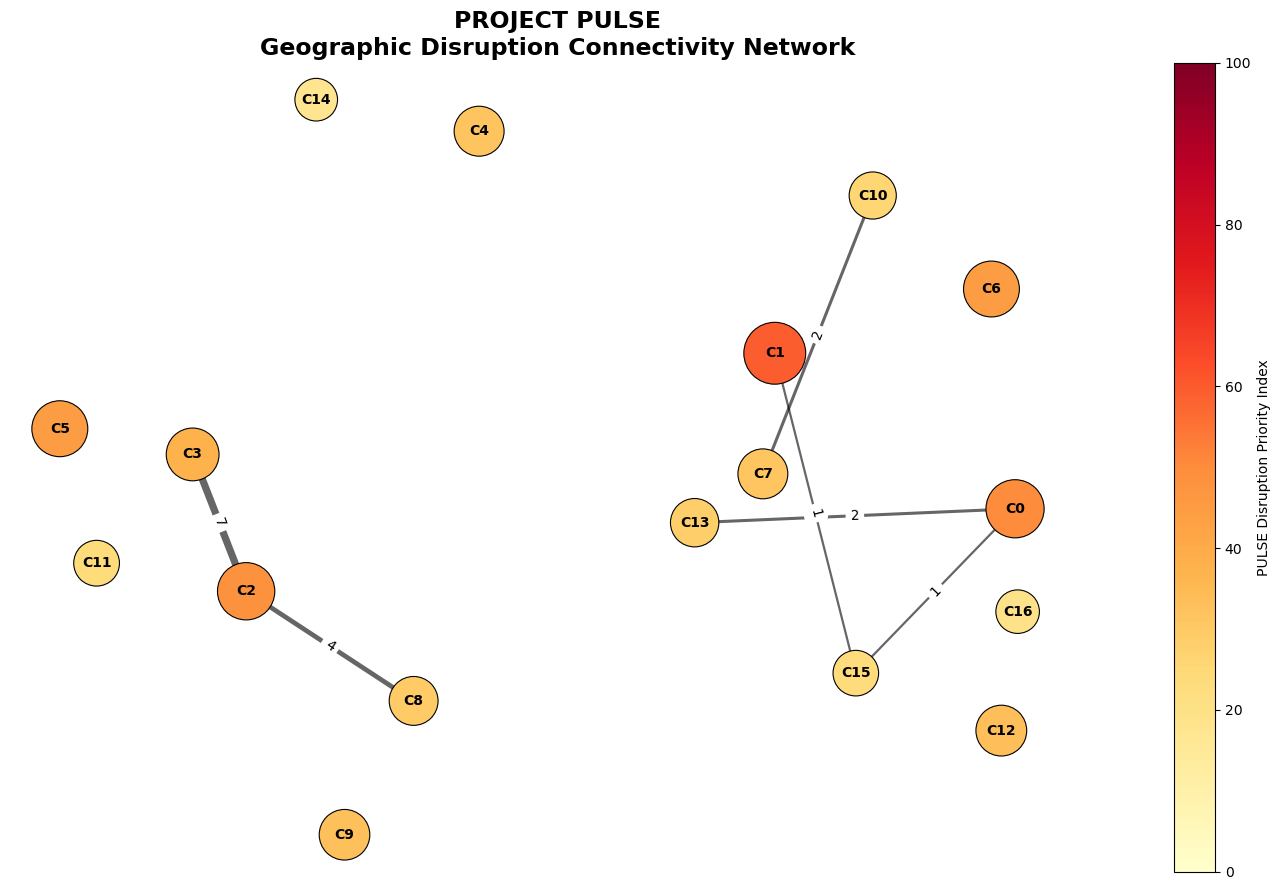

In [ ]:
# Visualize PULSE Network Graph

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 9))

positions = nx.spring_layout(
    pulse_graph,
    seed=42,
    k=1.2,
    weight="weight"
)

node_sizes = [
    500 + pulse_graph.nodes[node]["priority"] * 25
    for node in pulse_graph.nodes()
]

node_colors = [
    pulse_graph.nodes[node]["priority"]
    for node in pulse_graph.nodes()
]

edge_widths = [
    1 + pulse_graph[u][v]["weight"] * 0.6
    for u, v in pulse_graph.edges()
]

nodes = nx.draw_networkx_nodes(
    pulse_graph,
    positions,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.YlOrRd,
    vmin=0,
    vmax=100,
    edgecolors="black",
    linewidths=0.8,
    ax=ax
)

nx.draw_networkx_edges(
    pulse_graph,
    positions,
    width=edge_widths,
    alpha=0.6,
    ax=ax
)

nx.draw_networkx_labels(
    pulse_graph,
    positions,
    labels={
        node: f"C{node}"
        for node in pulse_graph.nodes()
    },
    font_size=10,
    font_weight="bold",
    ax=ax
)

nx.draw_networkx_edge_labels(
    pulse_graph,
    positions,
    edge_labels=nx.get_edge_attributes(
        pulse_graph, "weight"
    ),
    font_size=10,
    ax=ax
)

fig.colorbar(
    nodes,
    ax=ax,
    label="PULSE Disruption Priority Index"
)

ax.set_title(
    "PROJECT PULSE\nGeographic Disruption Connectivity Network",
    fontsize=17,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()
plt.show()

## 7. Official service alerts
Live alerts provide route-level context only; they may be newer than the prediction snapshot. The following cells call the API. Some alert route IDs do not match the inventory.

In [ ]:
# Retrieve MBTA Service Alerts

import requests
import pandas as pd

url = "https://api-v3.mbta.com/alerts"

response = requests.get(
    url,
    params={"page[limit]": 100},
    timeout=30
)

response.raise_for_status()

alert_data = response.json()

print("HTTP Status:", response.status_code)
print("Alerts on first page:", len(alert_data["data"]))
print("Next page:", (alert_data.get("links") or {}).get("next"))

HTTP Status: 200
Alerts on first page: 100
Next page: https://api-v3.mbta.com/alerts?page[limit]=100&page[offset]=100


In [ ]:
# Identify Active MBTA Alerts

import time

all_alerts = list(alert_data["data"])
next_url = (alert_data.get("links") or {}).get("next")

while next_url:
    time.sleep(1)

    response = requests.get(next_url, timeout=30)
    response.raise_for_status()

    payload = response.json()
    all_alerts.extend(payload.get("data", []))

    next_url = (payload.get("links") or {}).get("next")

now = pd.Timestamp.now(tz="UTC")

active_records = []

for alert in all_alerts:

    attrs = alert["attributes"]

    for period in attrs.get("active_period") or []:

        start = pd.to_datetime(
            period.get("start"), utc=True
        )

        end = pd.to_datetime(
            period.get("end"), utc=True
        )

        if (
            (pd.isna(start) or start <= now)
            and
            (pd.isna(end) or end > now)
        ):

            active_records.append({
                "alert_id": alert["id"],
                "effect": attrs.get("effect"),
                "cause": attrs.get("cause"),
                "severity": attrs.get("severity"),
                "header": attrs.get("header"),
                "informed_entity": attrs.get("informed_entity"),
                "collected_at": now
            })

            break

df_active_alerts = pd.DataFrame(
    active_records,
    columns=[
        "alert_id", "effect", "cause",
        "severity", "header",
        "informed_entity", "collected_at"
    ]
).drop_duplicates(subset=["alert_id"])

print("Total retrieved alerts:",
      len({a["id"] for a in all_alerts}))

print("Currently active alerts:",
      len(df_active_alerts))

display(df_active_alerts.head(10))

Total retrieved alerts: 170
Currently active alerts: 153


,alert_id,effect,cause,severity,header,informed_entity,collected_at
0,1001814,STATION_ISSUE,UNKNOWN_CAUSE,1,The platform at Jackson Square is undergoing r...,"[{'stop': '70006', 'route': 'Orange', 'route_t...",2026-11-24 23:57:25.182288+00:00
1,1046615,BIKE_ISSUE,UNKNOWN_CAUSE,3,The west bike cage at Alewife will be closed d...,"[{'stop': '14112', 'route': '350', 'route_type...",2026-11-24 23:57:25.182288+00:00
2,1033322,ELEVATOR_CLOSURE,UNKNOWN_CAUSE,8,South Acton Elevator 704 (Track 1 (outbound pl...,"[{'stop': 'FR-0253-01', 'route': 'CR-Fitchburg...",2026-11-24 23:57:25.182288+00:00
3,1047340,DELAY,TRAFFIC,5,Route 80 is experiencing delays of about 20 mi...,"[{'route': '80', 'route_type': 3, 'activities'...",2026-11-24 23:57:25.182288+00:00
4,1009804,ESCALATOR_CLOSURE,MAINTENANCE,3,Alewife Escalator 351 (Main concourse to platf...,"[{'stop': 'place-alfcl', 'route': '350', 'rout...",2026-11-24 23:57:25.182288+00:00
5,1047411,ELEVATOR_CLOSURE,MAINTENANCE,3,Chinatown Elevator 876 (Oak Grove platform to ...,"[{'stop': '70019', 'route': 'Orange', 'route_t...",2026-11-24 23:57:25.182288+00:00
6,1047315,DELAY,TRAFFIC,5,Route 36 is experiencing delays of about 20 mi...,"[{'route': '36', 'route_type': 3, 'activities'...",2026-11-24 23:57:25.182288+00:00
7,1047376,DELAY,TRAFFIC,5,Route 88 is experiencing delays of about 20 mi...,"[{'route': '88', 'route_type': 3, 'activities'...",2026-11-24 23:57:25.182288+00:00
8,1047375,DELAY,TRAFFIC,5,Route 87 is experiencing delays of about 20 mi...,"[{'route': '87', 'route_type': 3, 'activities'...",2026-11-24 23:57:25.182288+00:00
9,1024904,ESCALATOR_CLOSURE,MAINTENANCE,3,Courthouse Escalator 418 (Lobby to Seaport Bou...,"[{'stop': '74612', 'route': '741', 'route_type...",2026-11-24 23:57:25.182288+00:00


In [ ]:
# Route and Service Alert Integration

route_alert_records = []

for _, alert in df_active_alerts.iterrows():

    for entity in alert["informed_entity"] or []:

        route_id = entity.get("route")

        if route_id:

            route_alert_records.append({
                "alert_id": alert["alert_id"],
                "route_id": route_id,
                "effect": alert["effect"],
                "cause": alert["cause"],
                "severity": alert["severity"],
                "header": alert["header"]
            })

df_route_alerts = pd.DataFrame(
    route_alert_records,
    columns=[
        "alert_id", "route_id", "effect",
        "cause", "severity", "header"
    ]
).drop_duplicates(
    subset=["alert_id", "route_id"]
)

df_route_alerts = df_route_alerts.merge(
    df_network_routes[
        ["route_id", "route_name", "transit_mode"]
    ],
    on="route_id",
    how="left",
    validate="many_to_one"
)

print("Route-alert associations:",
      len(df_route_alerts))

print("Routes with active alerts:",
      df_route_alerts["route_id"].nunique())

display(
    df_route_alerts.sort_values(
        "severity", ascending=False
    ).head(15)
)

Route-alert associations: 326
Routes with active alerts: 137


,alert_id,route_id,effect,cause,severity,header,route_name,transit_mode
186,1047335,CR-Worcester,TRACK_CHANGE,UNKNOWN_CAUSE,8,Please board all inbound Worcester Line trains...,Framingham/Worcester Line,Commuter Rail
6,1033322,CR-Fitchburg,ELEVATOR_CLOSURE,UNKNOWN_CAUSE,8,South Acton Elevator 704 (Track 1 (outbound pl...,Fitchburg Line,Commuter Rail
260,1047249,441,DETOUR,CONSTRUCTION,7,Routes 441 and 442 are detoured due to constru...,Marblehead - Wonderland Station via Paradise Road,Bus
261,1047249,442,DETOUR,CONSTRUCTION,7,Routes 441 and 442 are detoured due to constru...,Marblehead - Wonderland Station via Humphrey S...,Bus
274,1047254,211,DETOUR,UNKNOWN_CAUSE,7,Route 211 is detoured. The closest stops with ...,Quincy Center Station - Squantum,Bus
292,1022195,220,DETOUR,CONSTRUCTION,7,Route 220 detoured due to construction. The cl...,Hingham Depot - Quincy Center Station,Bus
317,1001863,429,DETOUR,CONSTRUCTION,7,Route 429 outbound is detoured due to construc...,"Northgate Shopping Center - Central Square, Lynn",Bus
204,1047334,CR-Worcester,TRACK_CHANGE,UNKNOWN_CAUSE,7,Please board all outbound Worcester/Framingham...,Framingham/Worcester Line,Commuter Rail
279,1026060,Green-E,STATION_CLOSURE,UNKNOWN_CAUSE,7,Green Line E Branch: Symphony station is close...,Green Line E,Light Rail
325,1047337,CR-Worcester,TRACK_CHANGE,UNKNOWN_CAUSE,7,Please board all inbound Framingham Line train...,Framingham/Worcester Line,Commuter Rail


In [ ]:
# Cluster and Service Alert Integration

df_cluster_alerts = df_cluster_routes.merge(
    df_route_alerts[
        [
            "route_id",
            "alert_id",
            "effect",
            "cause",
            "severity",
            "header"
        ]
    ],
    on="route_id",
    how="inner"
)

df_cluster_alerts = df_cluster_alerts.drop_duplicates(
    subset=["cluster_id", "route_id", "alert_id"]
)

df_cluster_alert_summary = (
    df_cluster_alerts
    .groupby("cluster_id")
    .agg(
        active_alerts=("alert_id", "nunique"),
        routes_with_alerts=("route_id", "nunique"),
        max_alert_severity=("severity", "max")
    )
    .reset_index()
)

df_pulse_intelligence = df_cluster_priority.merge(
    df_cluster_alert_summary,
    on="cluster_id",
    how="left",
    validate="one_to_one"
)

for column in [
    "active_alerts",
    "routes_with_alerts"
]:
    df_pulse_intelligence[column] = (
        df_pulse_intelligence[column]
        .fillna(0)
        .astype(int)
    )

display(
    df_pulse_intelligence[
        [
            "cluster_id",
            "total_hotspots",
            "total_routes",
            "avg_deviation_min",
            "pulse_dpi",
            "active_alerts",
            "routes_with_alerts",
            "max_alert_severity"
        ]
    ].round(2)
)

,cluster_id,total_hotspots,total_routes,avg_deviation_min,pulse_dpi,active_alerts,routes_with_alerts,max_alert_severity
0,1,6,2,21.83,59.38,2,2,5
1,0,47,9,14.69,50.16,8,8,7
2,2,16,8,14.18,48.13,8,7,7
3,5,26,10,10.33,44.88,7,7,5
4,6,41,17,6.36,44.72,13,16,6
5,3,6,7,11.35,37.75,8,6,7
6,12,3,4,7.49,33.49,1,1,5
7,9,9,6,8.46,33.09,6,4,5
8,4,5,2,11.25,31.75,6,2,5
9,7,19,4,9.38,31.63,3,3,7


## 8. Export results
Exports are written to a separate timestamped folder to avoid overwriting the original portfolio results.

In [ ]:
# Step 122: Export PULSE Analytical Results

from pathlib import Path

output_folder = Path("pulse_outputs") / pd.Timestamp.now(tz="UTC").strftime("%Y%m%d_%H%M%S")
output_folder.mkdir(parents=True, exist_ok=True)

pulse_exports = {
    "cluster_intelligence": df_pulse_intelligence,
    "cluster_routes": df_cluster_routes,
    "cluster_connections": df_cluster_edges,
    "network_centrality": df_network_centrality,
    "network_groups": df_network_groups,
    "active_alerts": df_active_alerts,
    "route_alerts": df_route_alerts,
    "cluster_alerts": df_cluster_alerts,
    "geographic_hotspots": df_hotspot_clusters
}

for name, dataframe in pulse_exports.items():

    file_path = output_folder / f"{name}.csv"

    dataframe.to_csv(file_path, index=False)

    print(f"Saved: {file_path}")

pulse_disruption_map.save(
    str(output_folder / "disruption_map.html")
)

pulse_cluster_map.save(
    str(output_folder / "cluster_map.html")
)

print("\nPULSE analytical exports complete!")

## 9. Collection engine and operations
The existing standalone collector is used by macOS launchd every 30 minutes. These definitions preserve the original collection and storage logic for inspection; they do not start collection. Do not run a second collector concurrently. The saved log shows HTTP 429 rate limits; successful unattended ingestion remains unverified.

In [ ]:
# Multi-Route Batch Collection Function

import time

def get_pulse_batch(route_ids):

    url = "https://api-v3.mbta.com/predictions"

    params = {
        "filter[route]": ",".join(route_ids),
        "include": "schedule",
        "page[limit]": 100
    }

    all_predictions = []
    schedules = {}
    pages = 0

    collected_at = pd.Timestamp.now(
        tz="America/New_York"
    )

    # Retrieve all prediction pages
    while url is not None:

        # Handle API rate limits
        for attempt in range(5):

            response = requests.get(
                url,
                params=params,
                timeout=30
            )

            if response.status_code == 429:

                retry_after = response.headers.get(
                    "Retry-After", ""
                )

                wait_time = (
                    int(retry_after)
                    if retry_after.isdigit()
                    else 5 * (2 ** attempt)
                )

                print(
                    f"Rate limit reached. "
                    f"Waiting {wait_time} seconds."
                )

                time.sleep(wait_time)

            else:
                break

        response.raise_for_status()

        payload = response.json()

        all_predictions.extend(
            payload.get("data", [])
        )

        # Store associated schedules
        for item in payload.get("included", []):

            if item["type"] == "schedule":

                schedules[item["id"]] = (
                    item["attributes"]
                )

        pages += 1

        url = (
            payload.get("links") or {}
        ).get("next")

        params = None

        time.sleep(0.5)

    # Process prediction records
    records = []

    for prediction in all_predictions:

        attrs = prediction["attributes"]
        rels = prediction["relationships"]

        def relationship_id(name):

            return (
                rels.get(name, {}).get("data") or {}
            ).get("id")

        schedule_id = relationship_id("schedule")

        schedule = schedules.get(schedule_id, {})

        records.append({

            "prediction_id": prediction["id"],
            "route_id": relationship_id("route"),
            "direction_id": attrs.get("direction_id"),
            "trip_id": relationship_id("trip"),
            "stop_id": relationship_id("stop"),
            "collected_at": collected_at,

            "predicted_arrival": attrs.get(
                "arrival_time"
            ),

            "predicted_departure": attrs.get(
                "departure_time"
            ),

            "scheduled_arrival": schedule.get(
                "arrival_time"
            ),

            "scheduled_departure": schedule.get(
                "departure_time"
            )
        })

    df = pd.DataFrame(records)

    # Handle empty responses
    if df.empty:

        print("No predictions available.")

        return df

    # Remove duplicate predictions
    df = df.drop_duplicates(
        subset=["prediction_id"],
        keep="last"
    ).copy()

    # Convert timestamps
    time_columns = [
        "predicted_arrival",
        "predicted_departure",
        "scheduled_arrival",
        "scheduled_departure"
    ]

    for column in time_columns:

        df[column] = pd.to_datetime(
            df[column],
            utc=True,
            errors="coerce"
        )

    # Calculate schedule deviations
    df["arrival_delay_min"] = (
        df["predicted_arrival"]
        - df["scheduled_arrival"]
    ).dt.total_seconds() / 60

    df["departure_delay_min"] = (
        df["predicted_departure"]
        - df["scheduled_departure"]
    ).dt.total_seconds() / 60

    print("\nBatch collection complete")
    print("Snapshot collected:", collected_at)
    print("Pages retrieved:", pages)
    print("Routes requested:", len(route_ids))
    print("Routes returned:", df["route_id"].nunique())
    print("Raw predictions:", len(all_predictions))
    print("Unique predictions:", len(df))
    print("Unique schedules:", len(schedules))

    return df

In [ ]:
# PULSE Unified Collection Engine

def collect_pulse_network(batch_size=10):

    all_routes = df_network_routes["route_id"].tolist()

    collected_frames = []
    failed_batches = []

    total_batches = (
        len(all_routes) + batch_size - 1
    ) // batch_size

    collection_start = pd.Timestamp.now(
        tz="America/New_York"
    )

    print("Starting PULSE network collection")
    print("Total routes:", len(all_routes))
    print("Total batches:", total_batches)

    for i in range(0, len(all_routes), batch_size):

        batch = all_routes[i:i + batch_size]

        batch_number = i // batch_size + 1

        print(
            f"\nProcessing batch "
            f"{batch_number}/{total_batches}"
        )

        try:

            df_batch = get_pulse_batch(batch)

            if not df_batch.empty:

                collected_frames.append(df_batch)

        except Exception as error:

            failed_batches.append(batch)

            print("Batch failed:", error)

        time.sleep(3)

    if not collected_frames:

        print("No predictions collected.")

        return pd.DataFrame(), failed_batches

    df_network = pd.concat(
        collected_frames,
        ignore_index=True
    )

    df_network = df_network.drop_duplicates(
        subset=["prediction_id"],
        keep="last"
    ).copy()

    df_network = df_network.merge(
        df_network_routes,
        on="route_id",
        how="left",
        validate="many_to_one"
    )

    collection_end = pd.Timestamp.now(
        tz="America/New_York"
    )

    print("\nPULSE COLLECTION COMPLETE")
    print("-" * 40)

    print("Total predictions:", len(df_network))

    print(
        "Unique routes:",
        df_network["route_id"].nunique()
    )

    print("Failed batches:", len(failed_batches))

    print(
        "Collection duration:",
        collection_end - collection_start
    )

    return df_network, failed_batches


print("PULSE collection engine ready!")

In [ ]:
# PULSE Database Storage Function

def save_pulse_snapshot(df_network):

    if df_network.empty:
        print("No predictions available to save.")
        return None

    df_db = df_network.copy()

    time_columns = [
        "collected_at",
        "predicted_arrival",
        "predicted_departure",
        "scheduled_arrival",
        "scheduled_departure"
    ]

    for column in time_columns:

        df_db[column] = pd.to_datetime(
            df_db[column],
            utc=True,
            errors="coerce"
        ).dt.strftime("%Y-%m-%dT%H:%M:%S.%fZ")

    if df_db["collected_at"].isna().any():
        raise ValueError("Missing collection timestamps.")

    collection_start = df_db["collected_at"].min()
    collection_end = df_db["collected_at"].max()

    prediction_columns = [
        "prediction_id",
        "route_id",
        "direction_id",
        "trip_id",
        "stop_id",
        "collected_at",
        "predicted_arrival",
        "predicted_departure",
        "scheduled_arrival",
        "scheduled_departure",
        "arrival_delay_min",
        "departure_delay_min"
    ]

    df_insert = df_db[prediction_columns].astype(object)

    df_insert = df_insert.where(
        pd.notna(df_insert),
        None
    )

    with conn:

        existing = conn.execute(
            """
            SELECT snapshot_id
            FROM snapshots
            WHERE collection_start = ?
              AND collection_end = ?
            """,
            (collection_start, collection_end)
        ).fetchone()

        if existing:

            print("Snapshot already exists.")
            print("Snapshot ID:", existing[0])

            return existing[0]

        cursor = conn.execute(
            """
            INSERT INTO snapshots (
                collection_start,
                collection_end,
                total_predictions
            )
            VALUES (?, ?, ?)
            """,
            (
                collection_start,
                collection_end,
                len(df_db)
            )
        )

        new_snapshot_id = cursor.lastrowid

        prediction_records = [
            (new_snapshot_id, *row)
            for row in df_insert.itertuples(
                index=False,
                name=None
            )
        ]

        conn.executemany(
            """
            INSERT INTO predictions (
                snapshot_id,
                prediction_id,
                route_id,
                direction_id,
                trip_id,
                stop_id,
                collected_at,
                predicted_arrival,
                predicted_departure,
                scheduled_arrival,
                scheduled_departure,
                arrival_delay_min,
                departure_delay_min
            )
            VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
            """,
            prediction_records
        )

    print("Snapshot successfully stored!")
    print("Snapshot ID:", new_snapshot_id)
    print("Predictions stored:", len(df_db))

    return new_snapshot_id


print("PULSE database storage engine ready!")

In [ ]:
# PULSE Automated Data Pipeline

def run_pulse_pipeline(batch_size=10):

    print("=" * 50)
    print("PROJECT PULSE - NETWORK DATA PIPELINE")
    print("=" * 50)

    # 1. Collect network predictions

    df_network, failed_batches = collect_pulse_network(
        batch_size=batch_size
    )

    if df_network.empty:
        print("Pipeline stopped: No data collected.")
        return None

    # 2. Validate collected data

    print("\nValidating collected data...")

    duplicate_count = df_network[
        "prediction_id"
    ].duplicated().sum()

    missing_modes = df_network[
        "transit_mode"
    ].isna().sum()

    if duplicate_count > 0 or missing_modes > 0:
        print("Pipeline stopped: Data validation failed.")
        return None

    total_routes = df_network_routes["route_id"].nunique()

    collected_routes = df_network["route_id"].nunique()

    coverage = collected_routes / total_routes * 100

    # 3. Save CSV backup

    data_folder = Path("pulse_data")
    data_folder.mkdir(exist_ok=True)

    timestamp = pd.Timestamp.now(
        tz="America/New_York"
    ).strftime("%Y%m%d_%H%M%S_%f")

    backup_path = (
        data_folder / f"pulse_network_{timestamp}.csv"
    )

    df_network.to_csv(backup_path, index=False)

    print("CSV backup saved:", backup_path)

    # 4. Check for collection failures

    if failed_batches:
        print("Pipeline stopped: Some batches failed.")
        print("Failed batches:", failed_batches)
        print("Partial collection preserved in CSV.")
        return None

    # 5. Store historical snapshot

    new_snapshot_id = save_pulse_snapshot(df_network)

    # 6. Display pipeline summary

    print("\nPULSE PIPELINE SUMMARY")
    print("-" * 40)

    print("Snapshot ID:", new_snapshot_id)
    print("Total predictions:", len(df_network))
    print("Routes collected:", collected_routes)
    print("Network coverage:", round(coverage, 2), "%")
    print("Duplicate predictions:", duplicate_count)
    print("Missing classifications:", missing_modes)
    print("Failed batches:", len(failed_batches))

    print("\nPredictions by transportation mode:")
    print(df_network["transit_mode"].value_counts())

    print("\nPipeline completed successfully!")

    return new_snapshot_id


print("PULSE automated pipeline ready!")

In [ ]:
for filename in ["collector.log", "errors.log"]:
    log = Path("pulse_logs") / filename
    print(f"\n--- {filename} ---")
    if log.exists():
        print("\n".join(log.read_text().splitlines()[-15:]))
display(pd.read_sql_query("SELECT * FROM snapshots ORDER BY snapshot_id", conn))

## 10. Conclusions and limitations
Initial results: 72,426 prediction observations across two collection windows, 234 potential hotspots, 17 spatial clusters and 153 active alerts. These are historical prototype results, not current network statistics. Predictive modeling is deferred until sufficient historical coverage exists. The scheduler refreshes predictions only; maps and alerts require separate analysis.

Source: [MBTA V3 API](https://api-v3.mbta.com/).